In [6]:
from board import NQueens
from cnf import CNFEncoder
from sat_solver import SATSolver
from min_conflicts import MinConflictsSolver
import matplotlib.pyplot as plt


In [7]:
# 1. Thí nghiệm SAT Solver (Glucose3)
print("Thí nghiệm SAT Solver (Glucose3):")
print("=" * 60)
print(f"{'N':<5} | {'Biến':<6} | {'Mệnh đề':<10} | {'Thời gian (ms)':<15} | {'Hợp lệ':<8}")
print("-" * 60)

sizes = [4, 8, 16, 32, 64]
sat_times = []

for n in sizes:
    problem = NQueens(n)
    solver = SATSolver()
    res = solver.solve(problem)
    ms = res.seconds * 1000
    sat_times.append(ms)
    builder = CNFEncoder(problem)
    valid = problem.valid(res.solution)
    print(f"{n:<5} | {n*n:<6} | {builder.clause_count():<10} | {ms:<15.4f} | {str(valid):<8}")
print("=" * 60)


Thí nghiệm SAT Solver (Glucose3):
N     | Biến   | Mệnh đề    | Thời gian (ms)  | Hợp lệ  
------------------------------------------------------------
4     | 16     | 80         | 0.0210          | True    
8     | 64     | 736        | 0.0404          | True    
16    | 256    | 6336       | 1.1330          | True    
32    | 1024   | 52608      | 12.0061         | True    
64    | 4096   | 428800     | 142.5773        | True    


In [8]:
# 2. Thí nghiệm Min-Conflicts (Standard vs Max-Conflict)
print("Thí nghiệm Min-Conflicts (20 lần chạy / kích thước):")
print("=" * 65)
print(f"{'N':<5} | {'Thuật toán':<22} | {'Bước TB':<10} | {'Thời gian (ms)':<15} | {'Tỷ lệ':<8}")
print("-" * 65)

mc_std_times = []
mc_std_steps = []
mc_max_times = []
mc_max_steps = []

for n in sizes:
    problem = NQueens(n)
    for alg in ['standard', 'max_conflict']:
        heuristic = (alg == 'max_conflict')
        steps_total = 0
        time_total = 0
        success = 0
        trials = 20
        for seed in range(trials):
            solver = MinConflictsSolver(heuristic=heuristic)
            res = solver.solve(problem, seed=2026 + seed)
            steps_total += res.steps
            time_total += res.seconds * 1000
            if res.solution and problem.valid(res.solution):
                success += 1

        avg_steps = steps_total / trials
        avg_time = time_total / trials
        if alg == 'standard':
            mc_std_times.append(avg_time)
            mc_std_steps.append(avg_steps)
        else:
            mc_max_times.append(avg_time)
            mc_max_steps.append(avg_steps)

        print(f"{n:<5} | {alg:<22} | {avg_steps:<10.1f} | {avg_time:<15.4f} | {success/trials*100:.0f}%")
print("=" * 65)


Thí nghiệm Min-Conflicts (20 lần chạy / kích thước):
N     | Thuật toán             | Bước TB    | Thời gian (ms)  | Tỷ lệ   
-----------------------------------------------------------------
4     | standard               | 7.4        | 0.0381          | 100%
4     | max_conflict           | 7.5        | 0.0498          | 100%
8     | standard               | 1103.2     | 3.3167          | 100%
8     | max_conflict           | 1575.5     | 5.3234          | 100%
16    | standard               | 95.6       | 0.5036          | 100%
16    | max_conflict           | 1084.7     | 5.9384          | 100%
32    | standard               | 97.2       | 0.9024          | 100%
32    | max_conflict           | 77.4       | 0.7720          | 100%
64    | standard               | 127.2      | 2.1329          | 100%
64    | max_conflict           | 112.0      | 2.0363          | 100%


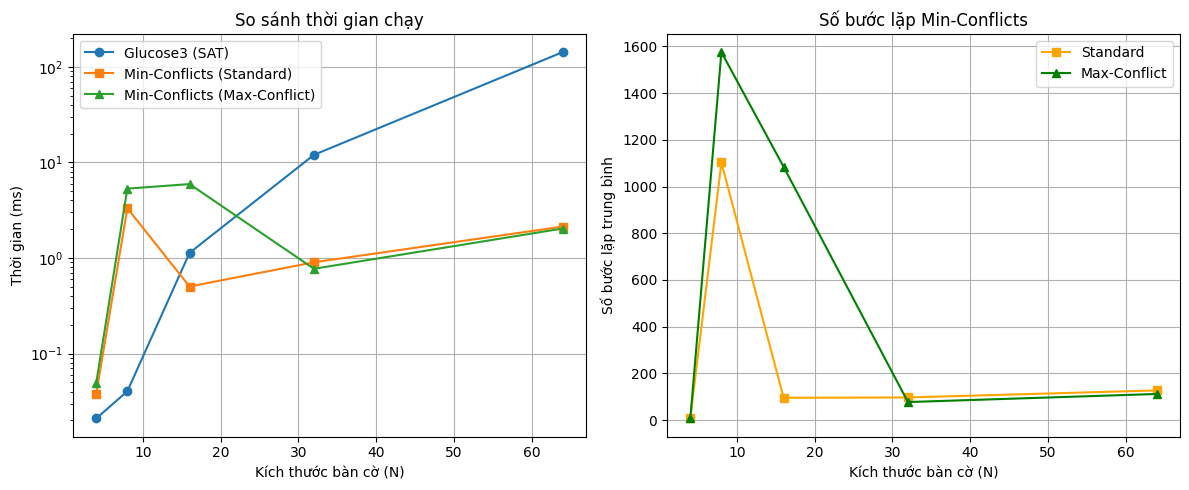

In [9]:
# 3. Vẽ đồ thị so sánh Thời gian và Số bước
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(sizes, sat_times, marker='o', label='Glucose3 (SAT)')
ax1.plot(sizes, mc_std_times, marker='s', label='Min-Conflicts (Standard)')
ax1.plot(sizes, mc_max_times, marker='^', label='Min-Conflicts (Max-Conflict)')
ax1.set_xlabel('Kích thước bàn cờ (N)')
ax1.set_ylabel('Thời gian (ms)')
ax1.set_title('So sánh thời gian chạy')
ax1.set_yscale('log')
ax1.grid(True)
ax1.legend()

ax2.plot(sizes, mc_std_steps, marker='s', color='orange', label='Standard')
ax2.plot(sizes, mc_max_steps, marker='^', color='green', label='Max-Conflict')
ax2.set_xlabel('Kích thước bàn cờ (N)')
ax2.set_ylabel('Số bước lặp trung bình')
ax2.set_title('Số bước lặp Min-Conflicts')
ax2.grid(True)
ax2.legend()

plt.tight_layout()
plt.show()
